# Assignment 2B — Copying a model with limited queries

You want to train your clothing classifier to sort out inventory at your store. However, you only have access to unlabeled clothing images as training data—and without labels it is difficult to train a supervised model. Fortunately, a third-party company offers a clothing classifier as a (black-box) service through an API. Your approach is to have the classifier label your data and then train your model on those labels, without access to the reference weights or internal features.

The data you will be using for this task is Fashion-MNIST, containing 60,000 training and 10,000 test images: 28 × 28 grayscale pixels across ten clothing classes. For this experiment, we will split the data as follows:

| Set | Size | Purpose |
|---|---:|---|
| Company's reference data | 50,000 | Provided reference setup only |
| Public query pool (`x_pool`) | 10,000 | Unlabeled inputs for training the copies |
| Evaluation set (official test set) | 10,000 | Final accuracy evaluation only |

Pixels are scaled to [0,1], and each input image has shape `(28, 28, 1)`. The company's private data trains the reference model. In the simulated attacker role, use only the public query pool to train your copies. Use the evaluation set (`x_test`, `y_test`) only to measure their performance.

The provided setup trains the reference locally to simulate a remote service; private data and weights are therefore present during setup, but are outside your permitted access in the copying tasks. Query the reference only through `QueryAPI`. Do not use its weights, internal features, private training data, or true public-pool labels. Never query or train on evaluation images. Do not reuse Part 1's collected labels or trained weights in Part 2.

**Complete all six YOUR WORK cells.** Model construction, prediction, API access, and final reporting displays are provided. You implement querying, selection, and training for your copies. Run the setup unchanged, then complete the numbered tasks in order.

## What you will do

In **Part 1**, you will ask the API to classify all 10,000 images in the public query pool, train a copy on those labels, and measure its test accuracy and agreement with the reference.
In **Part 2**, you will copy the model again with only **1,000 queries per strategy**, testing an adaptive sampling strategy against a random baseline.

| Part | Points |
|---|---:|
| 1. Copy using all 10,000 images | 30 |
| 2. Copy with 1,000 queries | 70 |

Each part is explained in detail in its own section below.

In [1]:
# PROVIDED SETUP AND DATA
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "4")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")
from pathlib import Path
import json, platform
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 302
MIN_ADAPTIVE_ADVANTAGE_PP = 1.0
OUTPUT = Path("outputs"); OUTPUT.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print(dict(python=platform.python_version(), tensorflow=tf.__version__, numpy=np.__version__))
(train_u8, train_labels), (test_u8, test_labels) = keras.datasets.fashion_mnist.load_data()
private_ids, public_ids = train_test_split(np.arange(60000), test_size=10000, stratify=train_labels, random_state=SEED)
def normalize(x): return x.astype("float32")[..., None] / 255.
x_private, y_private = normalize(train_u8[private_ids]), train_labels[private_ids]
x_pool = normalize(train_u8[public_ids])
x_test, y_test = normalize(test_u8), test_labels.astype("int64")
# No y_pool is created. Public true labels never enter extraction.
del train_u8, train_labels, test_u8, test_labels
assert not (set(private_ids) & set(public_ids))
print("Private / pool / test:",len(x_private),len(x_pool),len(x_test))

{'python': '3.12.12', 'tensorflow': '2.21.0', 'numpy': '2.5.5'}
Private / pool / test: 50000 10000 10000


## 0. Provided reference model

Run the provided setup unchanged. It trains the reference on the company's 50,000 private images for five epochs and caches its checkpoint. Later runs load the cache. Copies use the same small CNN but always start with fresh random weights. The reference API returns only a class label; the copy's own softmax probabilities remain available for local uncertainty ranking.

Use `make_model(SEED)` to create each fresh copy with the provided architecture, optimizer, and initialization seed. `predict_probabilities(model, images)` returns one row of ten class probabilities per image.


In [2]:
# PROVIDED MODEL AND REFERENCE TRAINING
def make_model(seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input(shape=(28,28,1)),
        layers.Conv2D(16,3,padding="same",activation="relu"),layers.MaxPooling2D(),
        layers.Conv2D(32,3,padding="same",activation="relu"),layers.MaxPooling2D(),
        layers.Flatten(),layers.Dense(64,activation="relu"),layers.Dense(10,activation="softmax")])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model

def predict_probabilities(model, images):
    return model.predict(images,batch_size=256,verbose=0)
cache = OUTPUT / "reference_private50k.keras"
if cache.exists(): reference_model = keras.models.load_model(cache)
else:
    reference_model = make_model(SEED)
    history = reference_model.fit(x_private,y_private,epochs=5,batch_size=256,verbose=2)
    reference_model.save(cache)
    (OUTPUT/'reference_history.json').write_text(json.dumps(history.history,indent=2))
reference_test_predictions = predict_probabilities(reference_model,x_test).argmax(axis=1)
reference_accuracy = float(np.mean(reference_test_predictions == y_test))
print(f"Reference test accuracy: {reference_accuracy:.2%}")
reference_weights_before = [w.copy() for w in reference_model.get_weights()]
del x_private, y_private

Epoch 1/5


E0000 00:00:1795510208.791768 2129774 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


196/196 - 2s - 13ms/step - accuracy: 0.7668 - loss: 0.6765
Epoch 2/5
196/196 - 2s - 11ms/step - accuracy: 0.8566 - loss: 0.4013
Epoch 3/5
196/196 - 2s - 11ms/step - accuracy: 0.8743 - loss: 0.3540
Epoch 4/5
196/196 - 2s - 11ms/step - accuracy: 0.8839 - loss: 0.3261
Epoch 5/5
196/196 - 2s - 11ms/step - accuracy: 0.8905 - loss: 0.3053
Reference test accuracy: 88.16%


E0000 00:00:1795510219.903942 2129774 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


### Provided query API and training tools

`QueryAPI(budget).query(images)` accepts a stack of images shaped `(n, 28, 28, 1)` (or one image shaped `(28, 28, 1)`) and returns reference-predicted integer labels. It rejects repeats and over-budget requests. Each API instance tracks its own query count. The wrapper is a stand-in for remote model access, not an access-control boundary.

Use only images from `x_pool` in queries. The wrapper checks shape, repeats, and budget; following the pool-only restriction is your responsibility. The example below queries one public-pool image using a separate demonstration ledger. It does not supply labels to any assessed experiment.

A query means **one image sent to the reference**, not one Python function call. Sending 50 images costs 50 queries. `api.used` reports the number spent. Create a separate API instance for each experiment: a budget of 10,000 for Part 1 and a budget of 1,000 for each strategy in Part 2.

For Section 2.1, train the random baseline for `RANDOM_EPOCHS` (20 epochs) with optimizer batch size `BATCH_SIZE` (64). For Section 2.2, implement your own adaptive selection and training process. You choose the initial number of queried images, the number of new queries per round, and the training schedule. A query batch is the number of new images sent to the API; it is separate from the optimizer's training batch size.

The model-building and prediction helpers are provided, but the adaptive loop and checkpoint tracking are not. Use test images only for evaluation, never for selection or training.


In [3]:
# PROVIDED SCAFFOLDING
class QueryAPI:
    def __init__(self,budget): self.budget, self.seen = budget, set()
    @property
    def used(self): return len(self.seen)
    def query(self,images):
        images = np.asarray(images)
        if images.ndim == 3: images = images[None]
        if images.ndim != 4 or images.shape[1:] != x_pool.shape[1:]:
            raise ValueError("Images must be a stack of 28x28x1 images")
        keys = [img.tobytes() for img in images]
        if len(set(keys)) != len(keys) or self.seen & set(keys):
            raise ValueError("Do not query the same image twice")
        if self.used+len(keys)>self.budget: raise ValueError("Query budget exceeded")
        labels = predict_probabilities(reference_model,images).argmax(axis=1)
        self.seen.update(keys)
        return labels
RANDOM_EPOCHS = 20
QUERY_BUDGET = 1000
BATCH_SIZE = 64


Predicted class: Sneaker; queries used: 1


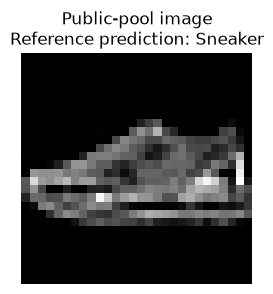

In [4]:
# PROVIDED API DEMONSTRATION — separate from all assessed query budgets.
demo_api = QueryAPI(budget=1)
demo_label = demo_api.query(x_pool[0])[0]
print(f"Predicted class: {CLASS_NAMES[demo_label]}; queries used: {demo_api.used}")
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(x_pool[0].squeeze(), cmap="gray")
ax.set_title(f"Public-pool image\nReference prediction: {CLASS_NAMES[demo_label]}")
ax.axis("off")
plt.show()


## Part 1 — Copy using all 10,000 images [30 points]

### 1.1. Query and train [20 points]

Use all 10,000 images in the public query pool (`x_pool`) to query the API for labels, then use those labels to train a fresh copy of the model (`full_model`). Keep your API instance as `full_api` for the query-count report.

In [5]:
# YOUR WORK — 1.1. Query all 10,000 public images and train a fresh copy.
full_api = None
full_model = None
raise NotImplementedError("Complete Part 1.1")

NotImplementedError: Complete Part 1.1

### 1.2. Evaluate [10 points]

Compute `full_report` with fields `queries`, `accuracy`, and `agreement`. Store accuracies as fractions in [0,1]. Accuracy compares the copy's test predictions to `y_test`; agreement compares them to `reference_test_predictions`. A copy can agree with a wrong reference prediction. Accuracy is the main assignment comparison; agreement adds information about copying fidelity.

| Field | Calculation |
|---|---|
| `queries` | `full_api.used` (10,000) |
| `accuracy` | Fraction of predictions equal to `y_test` |
| `agreement` | Fraction of predictions equal to `reference_test_predictions` |

Obtain predictions with `predict_probabilities(full_model, x_test).argmax(axis=1)`. Store fractions, not percentages; the provided displays format them as percentages.

In [ ]:
# YOUR WORK — 1.2. Calculate full-pool test accuracy and agreement.
# predict_probabilities(full_model, x_test).argmax(axis=1) gives predicted labels.
full_report = {"queries": None, "accuracy": None, "agreement": None}
raise NotImplementedError("Complete Part 1.2")

In [ ]:
# PROVIDED DISPLAY — run after completing full_report.
print("Full-pool copy report")
print(f"Queries:   {full_report['queries']:,}")
print(f"Accuracy:  {full_report['accuracy']:.2%}")
print(f"Agreement: {full_report['agreement']:.2%}")

## Part 2 — Copy with 1,000 queries [70 points]

After detecting excessive use, the company introduces a **1,000-image query limit**. Your goal is to copy the model under this limit by selecting 1,000 images from the 10,000-image public pool using two strategies: **random sampling** and **adaptive sampling**. Each strategy gets its own 1,000-query budget and produces a fresh copy of the model.

Use the same public pool, model architecture, initialization seed (`SEED`), and evaluation set for both strategies. Keep the random baseline at the provided training settings. Choose your initial sample count, query batch size, and adaptive training schedule. Do not reuse labels or trained weights from Part 1.

**Required result:** your adaptive copy must exceed the random baseline's test accuracy by **at least 1.0 percentage point**, measured on the same evaluation set.

### 2.1. Random baseline [25 points]

Randomly select 1,000 distinct images from `x_pool`, query the API for their labels, and train a fresh copy using the provided random-baseline settings (`RANDOM_EPOCHS` and `BATCH_SIZE`). Store your API instance as `random_api` and your trained model as `random_model`.

Evaluate `random_model` on `x_test` and complete `random_report` with the same fields as `full_report`: `queries` from `random_api.used`, `accuracy` against `y_test`, and `agreement` against `reference_test_predictions`. Store accuracy and agreement as fractions in [0,1].


In [6]:
# YOUR WORK — 2.1. Randomly select 1,000 images, query their labels, and train a fresh copy.
random_api = None
random_model = None
random_report = {"queries": None, "accuracy": None, "agreement": None}
raise NotImplementedError("Complete Part 2.1 and its report")

NotImplementedError: Complete Part 2.1

In [ ]:
# PROVIDED DISPLAY — run after completing random_report.
print("Random baseline report")
print(f"Queries:   {random_report['queries']:,}")
print(f"Accuracy:  {random_report['accuracy']:.2%}")
print(f"Agreement: {random_report['agreement']:.2%}")

### 2.2. Adaptive uncertainty sampling [45 points]

Implement an adaptive strategy that uses your current copy's uncertainty to choose which images to query next:

1. **Choose an initial set.** Randomly select a nonempty initial subset of fewer than 1,000 images of `x_pool` and query the API for its labels. You decide how many images to start with; these queries count toward your 1,000-query budget.
2. **Train your initial copy.** Create a fresh model using the provided architecture and `SEED`, then train it on the images and API labels collected so far.
3. **Assess uncertainty.** Run the remaining, unqueried pool images through **your trained copy** to obtain class probabilities and assess each image's uncertainty. One way to rank uncertainty is the **prediction margin**: the largest probability minus the second-largest probability for each image. A small margin means the copy has difficulty choosing between its two most likely classes.

   | Image | Copy's two highest probabilities | Margin | Interpretation |
   |---|---|---:|---|
   | A | Shirt: 0.48; T-shirt/top: 0.45 | 0.03 | Uncertain: the two classes are nearly tied |
   | B | Shirt: 0.92; T-shirt/top: 0.04 | 0.88 | Confident: one class has a strong lead |

   With margin-based selection, query **image A before image B** in the next round, as its reference label may help the copy resolve an ambiguity. You may use a different uncertainty heuristic.

4. **Select and query more images.** Choose a batch of images your copy is uncertain about and request their labels from the API. You decide the batch size and uncertainty criterion; each batch must fit within your remaining query budget.
5. **Update your copy and repeat.** Add the newly labeled images to your collected training data and continue training. Reassess uncertainty and select the next batch using the updated copy. Repeat until you have used **1,000 total queries**, including the initial set. Query each selected image only once.
6. **Record your outputs.** Store your API instance as `adaptive_api` and your final copy as `adaptive_model`.
7. **Evaluate and report.** Evaluate `adaptive_model` on `x_test` and complete `adaptive_report` with the same fields as `full_report`: `queries` from `adaptive_api.used`, `accuracy` against `y_test`, and `agreement` against `reference_test_predictions`. Store accuracy and agreement as fractions in [0,1].

**Required result:** your adaptive copy must exceed the random baseline's test accuracy by **at least 1.0 percentage point**.


In [ ]:
# YOUR WORK — 2.2. Implement your uncertainty-based image-selection strategy.
# You may define your own helper functions and interfaces.
raise NotImplementedError("Implement adaptive selection")

In [ ]:
# YOUR WORK — 2.2. Implement adaptive querying and training within 1,000 total queries.
adaptive_api = None
adaptive_model = None
raise NotImplementedError("Implement adaptive extraction")

In [ ]:
# YOUR WORK — 2.2. Evaluate your adaptive copy and complete its report.
adaptive_report = {"queries": None, "accuracy": None, "agreement": None}
raise NotImplementedError("Complete the adaptive report")

In [ ]:
# PROVIDED DISPLAY — run after completing adaptive_report.
print("Adaptive copy report")
print(f"Queries:   {adaptive_report['queries']:,}")
print(f"Accuracy:  {adaptive_report['accuracy']:.2%}")
print(f"Agreement: {adaptive_report['agreement']:.2%}")

### Compare the results — provided code

After completing the reports in Sections 2.1 and 2.2, run the following cells to display the results alongside Part 1, generate `comparison_report`, and check the required **1.0-percentage-point adaptive advantage**. You do not need to implement the comparison code.

The advantage is `100 * (adaptive_accuracy - random_accuracy)`, using unrounded accuracies. This is an absolute difference in percentage points, not a relative percentage improvement. The methods have equal query budgets, but their training schedules may differ.


In [ ]:
# PROVIDED COMPARISON — run after completing all three reports.
# Check report units and query counts before displaying the comparison.
for name, report, api, expected_queries in [
    ("Full pool", full_report, full_api, 10000),
    ("Random", random_report, random_api, QUERY_BUDGET),
    ("Adaptive", adaptive_report, adaptive_api, QUERY_BUDGET),
]:
    assert api.used == expected_queries, f"{name}: expected {expected_queries} queries, got {api.used}"
    assert report["queries"] == api.used, f"{name}: report query count does not match API usage"
    for metric in ("accuracy", "agreement"):
        assert np.isfinite(report[metric]) and 0 <= report[metric] <= 1, f"{name}: {metric} must be a fraction in [0,1]"

comparison_report = {
    "reference_accuracy": reference_accuracy,
    "full_accuracy": full_report["accuracy"],
    "random_accuracy": random_report["accuracy"],
    "adaptive_accuracy": adaptive_report["accuracy"],
    "adaptive_minus_random_pp": 100 * (adaptive_report["accuracy"] - random_report["accuracy"]),
}
print("Comparison report:", comparison_report)


In [ ]:
# PROVIDED DISPLAYS
reports = {'Full pool':full_report,'Random':random_report,'Adaptive':adaptive_report}
print(f"{'Model':15} {'Queries':>8} {'Accuracy':>12} {'Agreement':>12}")
print(f"{'Reference':15} {'—':>8} {reference_accuracy:12.2%} {'—':>12}")
for name,r in reports.items(): print(f"{name:15} {r['queries']:8d} {r['accuracy']:12.2%} {r['agreement']:12.2%}")
# PROVIDED REQUIREMENT CHECK — verify reported metrics and recompute the advantage.
checked_random_accuracy = float(np.mean(predict_probabilities(random_model,x_test).argmax(axis=1) == y_test))
checked_adaptive_accuracy = float(np.mean(predict_probabilities(adaptive_model,x_test).argmax(axis=1) == y_test))
for name, model, report in [("Full pool", full_model, full_report),
                            ("Random", random_model, random_report),
                            ("Adaptive", adaptive_model, adaptive_report)]:
    predictions = predict_probabilities(model, x_test).argmax(axis=1)
    assert np.isclose(report["accuracy"], np.mean(predictions == y_test), rtol=0, atol=1e-8), f"{name}: incorrect reported accuracy"
    assert np.isclose(report["agreement"], np.mean(predictions == reference_test_predictions), rtol=0, atol=1e-8), f"{name}: incorrect reported agreement"
checked_gain_pp = 100 * (checked_adaptive_accuracy - checked_random_accuracy)
# Compare correct-count differences to avoid floating-point ambiguity at exactly 1 pp.
required_extra_correct = int(np.ceil(len(y_test) * MIN_ADAPTIVE_ADVANTAGE_PP / 100))
extra_correct = int(round((checked_adaptive_accuracy - checked_random_accuracy) * len(y_test)))
advantage_requirement_met = extra_correct >= required_extra_correct
print(f"Adaptive advantage: {checked_gain_pp:.2f} percentage points; required: >= {MIN_ADAPTIVE_ADVANTAGE_PP:.2f}")
print("Requirement:", "MET" if advantage_requirement_met else "NOT MET")
